# Đồ thị 07 Violin phân bố tuổi theo giới tính

**Võ Minh Huy — 2311110117**

Dùng đủ 299 hồ sơ sau tiền xử lý; sex = 0 là nữ, sex = 1 là nam. Không cần nhãn DEATH_EVENT nên hồ sơ chờ xác minh nhãn vẫn tham gia hình. Violin biểu diễn mật độ tuổi trong từng nhóm, kèm median và khoảng Q1–Q3.

Hai violin có cùng chiều rộng tối đa để so sánh hình dạng, không biểu diễn tỷ lệ số hồ sơ. Cỡ nhóm được ghi riêng ở nhãn trục X. KDE dùng bandwidth Scott cho từng nhóm và chỉ vẽ trong khoảng tuổi quan sát của nhóm.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
for cot in ["age", "sex"]:
    du_lieu[cot] = pd.to_numeric(du_lieu[cot], errors="raise")
if len(du_lieu) != 299 or du_lieu[["age","sex"]].isna().any().any():
    raise ValueError("Cần đủ 299 hồ sơ không thiếu tuổi hoặc sex.")
assert du_lieu["sex"].isin([0,1]).all()
assert du_lieu["age"].between(40,95).all()
assert np.isfinite(du_lieu["age"]).all()
assert du_lieu["sex"].value_counts().to_dict() == {1:194,0:105}
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/07_violin_age_sex"
thu_muc_kq.mkdir(parents=True, exist_ok=True)
dong_thong_ke = []
mau = []
for sex, gioi_tinh in [(0,"Nữ"),(1,"Nam")]:
    tuoi = du_lieu.loc[du_lieu["sex"].eq(sex),"age"]
    mau.append(tuoi.to_numpy())
    dong_thong_ke.append({"sex":sex,"GioiTinh":gioi_tinh,"SoHoSo":len(tuoi),
        "Min":tuoi.min(),"Q1":tuoi.quantile(0.25),"Median":tuoi.median(),
        "Q3":tuoi.quantile(0.75),"Max":tuoi.max(),"Mean":tuoi.mean(),
        "BandwidthScottNam":tuoi.std(ddof=1)*len(tuoi)**(-1/5)})
thong_ke = pd.DataFrame(dong_thong_ke)
assert thong_ke["SoHoSo"].sum() == 299
thong_ke.round(2)


,sex,GioiTinh,SoHoSo,Min,Q1,Median,Q3,Max,Mean,BandwidthScottNam
0,0,Nữ,105,40.0,50.0,60.0,65.0,95.0,59.74,4.31
1,1,Nam,194,40.0,53.0,60.0,69.0,95.0,61.29,3.98


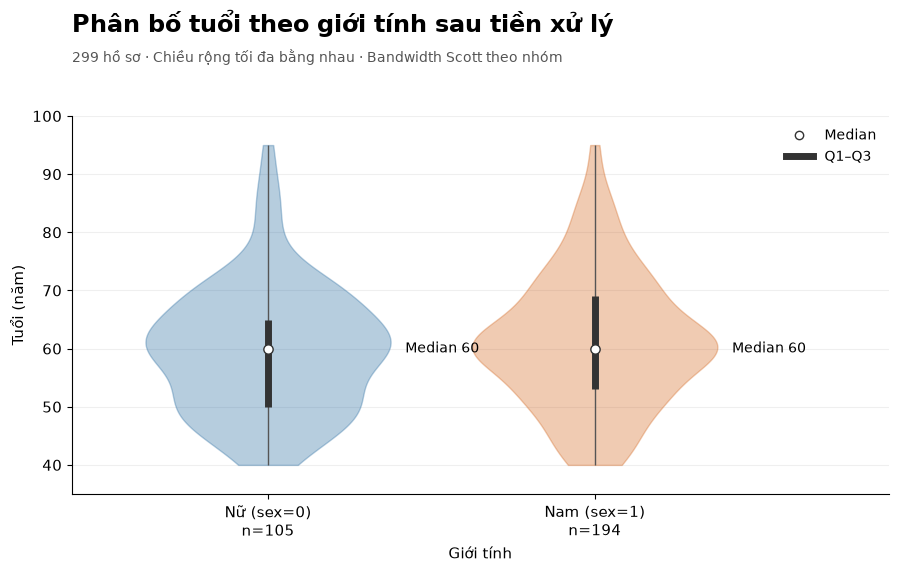

In [2]:
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11})
fig, ax = plt.subplots(figsize=(9.5,6))
fig.subplots_adjust(top=0.80,bottom=0.17,left=0.11,right=0.97)
fig.text(0.11,0.94,"Phân bố tuổi theo giới tính sau tiền xử lý",fontsize=17,weight="bold")
fig.text(0.11,0.89,"299 hồ sơ · Chiều rộng tối đa bằng nhau · Bandwidth Scott theo nhóm",color="#555555",fontsize=10)
v = ax.violinplot(mau,positions=[1,2],widths=0.75,points=200,
    showmeans=False,showmedians=False,showextrema=False,bw_method="scott")
for than, mau_sac in zip(v["bodies"],["#2E70A3","#D46A24"]):
    than.set_facecolor(mau_sac)
    than.set_edgecolor(mau_sac)
    than.set_alpha(0.35)
for vi_tri, r in enumerate(thong_ke.to_dict("records"),start=1):
    ax.vlines(vi_tri,r["Min"],r["Max"],color="#555555",linewidth=1)
    ax.vlines(vi_tri,r["Q1"],r["Q3"],color="#333333",linewidth=5)
    ax.scatter(vi_tri,r["Median"],s=45,color="white",edgecolor="#333333",zorder=3)
    ax.text(vi_tri+0.42,r["Median"],f'Median {r["Median"]:g}',va="center",fontsize=10)
ax.set_xticks([1,2],labels=[f'Nữ (sex=0)\nn={len(mau[0])}',f'Nam (sex=1)\nn={len(mau[1])}'])
ax.set(xlabel="Giới tính",ylabel="Tuổi (năm)",ylim=(35,100),xlim=(0.4,2.9))
ax.set_yticks(np.arange(40,101,10))
ax.grid(axis="y",alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.legend(handles=[Line2D([],[],marker="o",color="#333333",markerfacecolor="white",linestyle="",label="Median"),
    Line2D([],[],color="#333333",linewidth=5,label="Q1–Q3")],frameon=False,loc="upper right",fontsize=10)
fig.savefig(thu_muc_kq / "07_violin_age_sex.png",dpi=300,bbox_inches="tight",facecolor="white")
thong_ke.to_csv(thu_muc_kq / "thong_ke_python.csv",index=False,encoding="utf-8-sig")
du_lieu[["MaHoSo","age","sex"]].to_csv(thu_muc_kq / "du_lieu_ve_python.csv",index=False,encoding="utf-8-sig")
plt.show()


## Nhận xét

So sánh vị trí median, khoảng Q1–Q3 và hình dạng phân bố tuổi giữa hai nhóm. Phần violin rộng hơn thể hiện mật độ ước lượng cao hơn trong chính nhóm đó; không so chiều rộng để suy ra nhóm nào có nhiều hồ sơ hơn. Cỡ nhóm là nữ 105 và nam 194.

Hai phân bố tuổi có vùng chồng lấn; chỉ nhìn đồ thị chưa đủ kết luận có khác biệt thống kê. Hình dạng còn phụ thuộc bandwidth. Tuổi và sex đã qua xử lý, có cả các giá trị được điền ở N02 và N01; không xem toàn bộ là dữ liệu quan sát nguyên gốc. Giữ nguyên file after.
